# Probabilisitic 4-D Methanol synthesis loop

One run, top to bottom, from a fresh kernel:

- record the reactor inlet the loop produces and turn it into the surrogate's training box;
- sample the isolated PFR over that box and train surrogate `raw` (outlet flows directly);
- nested-sampling feasibility analysis on the surrogate loop, benchmarked against the same analysis on HYSYS.

HYSYS plumbing lives in `hysys.py`, `hysys_loop.py`, `hysys_pfr.py`, `hysys_surrogate.py`; sampling and the MLP in `helpers.py`.

In [1]:
# Imports
import time
import pickle
import itertools
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hysys import open_case
from helpers import generate_sobol_points, train_surrogate, NestedSampler, parity_plot, Corner, Trellis
import hysys_loop as loop            # full loop, PFR solved by HYSYS       (methanol_loop.hsc)
import hysys_pfr as pfr              # isolated reactor                     (methanol_pfr.hsc)
import hysys_surrogate as sur        # loop with the PFR replaced by a net  (methanol_surrogate.hsc)

from plotstyle import setup, save; setup()

In [2]:
# KNOBS
SMOKE_TEST = False                         # few points to check the machinery; False for the real run
SKIP_SENSITIVITY = True                    # whether or not to skip the sensitivity analysis (takes ~1 hour extra)
TAG = "_smoke" if SMOKE_TEST else ""       # suffix of every file this notebook writes

CASES = Path("C:/Users/kr326/Documents/cyclic-feasibility/hysys-meoh/AspenFiles")
CASE_LOOP = str(CASES / "methanol_loop.hsc")            # original flowsheet
CASE_PFR = str(CASES / "methanol_pfr.hsc")              # reactor with its inlet and outlet streams only
CASE_SUR = str(CASES / "methanol_surrogate.hsc")        # copy of the loop with Reactor100 ignored

# design variables; key order defines x = (T, P, ratio, purge) everywhere below
design_bounds = {"temperature_C": [220, 280], "pressure_bar": [70, 120],
                 "ratio": [2.5, 4.0], "purge_rate": [0.015, 0.08]}      # H2:CO2 fresh feed, purge fraction
VOLUME = 35                                        # fixed: reactor m3 (the nets are trained at one volume)
WARM_START = True                                  # start each tear at the nearest converged point
SEGMENTS = 10 if SMOKE_TEST else 50
INFLATE = 0.05                                     # widening of the reactor-inlet hull, both sides
RELAX   = 0.02                                     # constraint relaxation for surrogate feasibility analysis
NET = "stoi"                                       # surrogate in the feasibility analysis: "raw" or "stoi"

# constraints, feasible iff residual <= 0 (see constraints below)
MEOH_MIN = 18_000                  # kg/h methanol product
COMPRESSION_MAX = 4_000            # kW, syngas + recycle compressors
CO_MAX = 6                         # kgmole/h net CO formed in the reactor
H2_UTIL_MIN = 0.85                 # fraction of the fresh H2 not lost to the purge

# stage sizes
N_GRID = 9 if SMOKE_TEST else 30                            # A: points per axis of the T-P grid
N_HULL = 64 if SMOKE_TEST else 256                          # B: Sobol points of the loop for the inlet hull (4-D box)
N_PFR = 1024                                                # C: Sobol points of the reactor (power of two)
N_LIVE, N_PROP = (64, 16) if SMOKE_TEST else (512, 16)      # E: nested sampler (maintain this ratio for consistency with CSTR cascade)
N_LIVE_SUR = 2 * N_LIVE                                     # E: surrogate run; verification stops at N_LIVE confirmed
MAX_TIME = 7200 if SMOKE_TEST else 0                        # E: s wall time per sampler run (0: none)

In [3]:
# Setup: attach to the three cases (HYSYS is launched for any that is not open)
t0 = time.time()
case_loop, case_pfr, case_sur = (open_case(c) for c in (CASE_LOOP, CASE_PFR, CASE_SUR))
objects_loop = loop.cache_objects(case_loop, segments=SEGMENTS)
objects_pfr = pfr.cache_objects(case_pfr, segments=SEGMENTS)   # objects_sur needs the box from Part B
print(f"three cases attached in {time.time() - t0:.0f} s")

three cases attached in 1 s


In [4]:
# Loop adapters: design vector -> result row, the constraints on a row, and a sweep helper
WARM = {"hysys": [], "surrogate": []}        # (x, tear_state) of every converged point so far, per flowsheet

def nearest_state(x, seen):
    """Tear state of the converged point nearest to x; distances in box-normalised design coordinates."""
    if not WARM_START or not seen:
        return None
    X = np.array([p for p, _ in seen])
    span = np.array([hi - lo for lo, hi in design_bounds.values()])
    return seen[int((((X - x) / span) ** 2).sum(1).argmin())][1]

def row_hysys(x):
    T, P, ratio, purge = x
    row = loop.run_point(objects_loop, pressure=(P, "bar"), temperature=(T, "C"), volume=(VOLUME, "m3"),
                         ratio=ratio, purge_rate=purge, warm=nearest_state(x, WARM["hysys"]))
    if row["converged"]:
        WARM["hysys"].append((np.asarray(x, float), row["tear_state"]))
    return row

def h2_util(row):
    """Fraction of the fresh hydrogen that does not leave with the purge."""
    return 1 - row["hydrogen_purge_kg_h"] / row["h2_input_kg_h"]

def constraints(row, relax: float):
    """Residuals, feasible iff every value <= 0."""
    if not row["converged"]:
        raise RuntimeError("not converged")          # sampler drops the point, counts a failure
    return [MEOH_MIN * (1 - relax) - row["methanol_kg_h"],
            row["compression_kW"] - COMPRESSION_MAX * (1 + relax),
            row["co_formation_kgmole_h"] - CO_MAX * (1 + relax),
            H2_UTIL_MIN * (1 - relax) - h2_util(row)]

def loop_rows(points, model):
    """One row per design point; a point that raises is kept as not converged."""
    points = list(points)
    rows, t0 = [], time.time()
    num_pts = len(points)
    every = max(num_pts // 10, 1)
    for i, x in enumerate(points, start=1):
        try:
            rows.append({**model(x), **dict(zip(design_bounds, x))})    # set values win: exact grid keys
        except Exception as e:
            rows.append({**dict(zip(design_bounds, x)), "converged": False, "error": str(e)})
        if (i % every == 0 or i == num_pts):
            el = time.time() - t0
            print(f"{i}/{num_pts} {el/60:.1f} min elapsed")
    return pd.DataFrame(rows)


## Part A: loop exploration

In [5]:
if not SKIP_SENSITIVITY:
    # T-P grid of the loop at the nominal ratio 3, purge 0.03 and fixed volume
    T_axis = np.linspace(*design_bounds["temperature_C"], N_GRID)
    P_axis = np.linspace(*design_bounds["pressure_bar"], N_GRID)
    t0 = time.time()
    df_sweep = loop_rows(itertools.product(T_axis, P_axis, [3.0], [0.03]), row_hysys)
    print(f"{len(df_sweep)} points, {int(df_sweep.converged.sum())} converged, {time.time() - t0:.0f} s")

In [6]:
def heatmap(df, value, label, *, name,
            x="temperature_C", y="pressure_bar",
            levels=16, cmap="viridis", ax=None, title=None):
    """Heatmap of value over (x, y); non-converged cells are left blank."""
    if not df["converged"].all():
        print("Warning: Not all points converged")

    _df = df.copy()
    _df["value_plot"] = _df[value].where(_df["converged"])
    grid = _df.pivot(index=y, columns=x, values="value_plot")
    if ax is None:
        _, ax = plt.subplots(1, 1)
    mesh = ax.pcolormesh(grid.columns, grid.index, grid.values, cmap=cmap, shading="nearest")
    cs = ax.contour(grid.columns, grid.index, grid.values, levels=levels, colors="black", linewidths=1)
    ax.clabel(cs, fmt="%g")
    ax.set_xlabel(r"T [$^\circ$C]")
    ax.set_ylabel("Pressure [bar]")
    ax.set_title(title)
    ax.figure.colorbar(mesh, ax=ax, label=label)
    save(ax.figure, f"Cases/HYSYS_MeOH_4D/heatmap_{name}{TAG}")
    return ax

In [7]:
if not SKIP_SENSITIVITY:
    heatmap(df_sweep, "methanol_kg_h", "Methanol [kg/h]", title="Methanol production", levels=15, name="methanol")
    heatmap(df_sweep, "recycle_ratio", "Recycle ratio [-]", title="Recycle ratio", name="recycle_ratio")
    heatmap(df_sweep, "reactor_dP_bar", "Pressure drop (PFR) [bar]", title="Pressure drop", name="reactor_dP")
    heatmap(df_sweep, "co_formation_kgmole_h", "CO formation in PFR [kmol/h]", title="CO formation in PFR", name="co_formation")
    heatmap(df_sweep, "compression_kW", "Compression duty [kW]", title="Compression duty (K-100 & K-105)", name="compression");

## Part B: reactor-inlet domain, the surrogate's training box

In [8]:
# Sobol sample of the loop over the design box; run_point records the reactor inlet at each point
bounds = np.array(list(zip(*design_bounds.values())))          # 2 x d: lower row, upper row
t0 = time.time()
df_hull = loop_rows(generate_sobol_points(N_HULL, bounds), row_hysys)
t_hull = time.time() - t0                                       # s; per-solve cost of the loop for the benchmark
print(f"{len(df_hull)} points, {int(df_hull.converged.sum())} converged, {t_hull:.0f} s")

25/256 3.4 min elapsed


50/256 6.5 min elapsed


75/256 9.8 min elapsed


100/256 12.6 min elapsed


125/256 15.4 min elapsed


...

175/256 20.9 min elapsed


200/256 23.6 min elapsed


225/256 26.1 min elapsed


250/256 28.7 min elapsed


256/256 29.3 min elapsed
256 points, 256 converged, 1758 s


In [9]:
# Hull of the reactor inlet over the converged points, inflated -> training box in sur.INPUTS order
# NOTE: Units (Flows): kgmole/s
hull_ok = df_hull[df_hull["converged"]].reset_index(drop=True)
hull = {c: (hull_ok[f"in_{c}_kgmole_h"].min() / 3600, hull_ok[f"in_{c}_kgmole_h"].max() / 3600)   # kgmole/s
        for c in sur.COMPONENTS}
pfr_box = {**{k: design_bounds[k] for k in ("temperature_C", "pressure_bar")},     # ratio and purge reach the net only through the flows
           **{c: [max(lo - (hi - lo) * INFLATE, 0.0), hi + (hi - lo) * INFLATE] for c, (lo, hi) in hull.items()}}
assert list(pfr_box) == sur.INPUTS
pd.DataFrame(pfr_box, index=["lower", "upper"]).T

,lower,upper
temperature_C,220.000000,280.000000
pressure_bar,70.000000,120.000000
Hydrogen,0.779471,13.053845
CO,0.008336,0.362943
CO2,0.167050,1.418239
H2O,0.006749,0.013888
Methanol,0.001823,0.022321
Nitrogen,0.017638,0.114982


## Part C: PFR sampling and surrogate training

In [10]:
# Reactor sampling: vector in pfr_box order -> one HYSYS solve of the isolated PFR
def pfr_row(x):
    p = dict(zip(pfr_box, x))
    return pfr.run_point(objects_pfr, temperature=(p["temperature_C"], "C"), pressure=(p["pressure_bar"], "bar"),
                         volume=(VOLUME, "m3"), flows=({c: p[c] for c in sur.COMPONENTS}, "kgmole/s"))

def unit_sobol_sample(bounds, model, n_pts):
    lb = np.array([b[0] for b in bounds.values()])
    ub = np.array([b[1] for b in bounds.values()])
    input_var = generate_sobol_points(n=n_pts, bounds=np.stack((lb, ub)))
    results = []
    for iv in input_var:
        res = {**dict(zip(bounds, iv)), **model(iv)}
        results.append(res)
    return pd.DataFrame(results)

t0 = time.time()
df_pfr = unit_sobol_sample(pfr_box, pfr_row, N_PFR)
t_pfr = time.time() - t0                                       # s; per-solve cost of the PFR for the benchmark
print(f"{len(df_pfr)} evaluations, {int(df_pfr.converged.sum())} converged, {t_pfr:.0f} s")
df_pfr.to_csv(f"pfr_sobol{TAG}.csv", index=False)

1024 evaluations, 1024 converged, 52 s


In [ ]:
# Sampled design points in the T-P plane; the six flow dimensions are projected out
fig, ax = plt.subplots()
ax.scatter(df_pfr.temperature_C, df_pfr.pressure_bar, s=8)
ax.set(xlabel=r"T [$^\circ$C]", ylabel="P [bar]");


In [12]:
# Two surrogates of the same reactor, trained on the same inputs:
#   stoi: predicts the extents of the two independent reactions
#           xi1: CO2 + 3 H2 -> CH3OH + H2O      xi2: CO2 + H2 -> CO + H2O
#         plus duty and pressure drop; outlet = inlet + sur.STOICH @ extents, so the
#         atom balances hold by construction (sur.stoi_as_raw does that reconstruction).
#   raw:  predicts the six outlet flows plus duty and pressure drop directly.
# NOTE: key "Hydrogen" yields kgmole/s (analogous for other 5 components)
pfr_ok = df_pfr[df_pfr["converged"]].reset_index(drop=True)
X = pfr_ok[list(pfr_box)].to_numpy()                      # inputs in box order
Y_stoi = pd.DataFrame({
    "xi_meoh_kgmole_h": pfr_ok.out_Methanol_kgmole_h - pfr_ok.in_Methanol_kgmole_h,
    "xi_co_kgmole_h":   pfr_ok.out_CO_kgmole_h - pfr_ok.in_CO_kgmole_h,
    "reactor_duty_kW":  pfr_ok.reactor_duty_kW,
    "reactor_dP_bar":   pfr_ok.reactor_dP_bar,
})
Y_raw = pd.concat([pfr_ok[[f"out_{c}_kgmole_h" for c in sur.COMPONENTS]],
                   pfr_ok[["reactor_duty_kW", "reactor_dP_bar"]]], axis=1)
print(f"{len(X)} training points, {X.shape[1]} inputs -> stoi {Y_stoi.shape[1]} outputs, raw {Y_raw.shape[1]} outputs")

1024 training points, 8 inputs -> stoi 4 outputs, raw 8 outputs


In [13]:
t_train = {} # s, wall time of training per net
t0 = time.time()
stoi, rmse_stoi, oof_stoi = train_surrogate(X, Y_stoi, names=Y_stoi.columns, path=f"pfr_surrogate_stoi{TAG}.txt")
t_train["stoi"] = time.time() - t0
t0 = time.time()
raw, rmse_raw, oof_raw = train_surrogate(X, Y_raw, names=Y_raw.columns, path=f"pfr_surrogate_raw{TAG}.txt")
t_train["raw"] = time.time() - t0
nets = {"stoi": sur.stoi_as_raw(stoi), "raw": raw}       # both with the raw interface: outlet flows, duty, dP

width 64 (50 s)   CV rmse/std per width: 4: 0.2055, 8: 0.0642, 16: 0.0325, 32: 0.0247, 64: 0.0230, 128: 0.0325
  xi_meoh_kgmole_h           9.898    0.44 % of range
  xi_co_kgmole_h             9.285    0.55 % of range
  reactor_duty_kW          243.379    0.54 % of range
  reactor_dP_bar             0.008    0.19 % of range


width 64 (48 s)   CV rmse/std per width: 4: 0.3423, 8: 0.1190, 16: 0.0576, 32: 0.0275, 64: 0.0201, 128: 0.0223
  out_Hydrogen_kgmole_h    115.727    0.26 % of range
  out_CO_kgmole_h           10.184    0.83 % of range
  out_CO2_kgmole_h          13.590    0.29 % of range
  out_H2O_kgmole_h           7.953    0.35 % of range
  out_Methanol_kgmole_h     10.455    0.46 % of range
  out_Nitrogen_kgmole_h      1.053    0.30 % of range
  reactor_duty_kW          270.384    0.60 % of range
  reactor_dP_bar             0.011    0.24 % of range


out-of-fold RMSE of outlet flows [kgmole/h]:
             range  stoi_rmse  raw_rmse
Hydrogen  43837.13      26.07    115.73
CO         1227.85       9.28     10.18
CO2        4742.72       9.38     13.59
H2O        2287.58       9.38      7.95
Methanol   2283.14       9.90     10.45
Nitrogen    350.16       0.00      1.05

raw net atom balance error, out minus in [kgmole/h]  (stoi: zero by construction):
  C: rms   12.44   max   74.33
  O: rms   23.40   max  148.17
  H: rms  223.84   max  984.02


WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH_4D/parity_pfr_outlets.png')

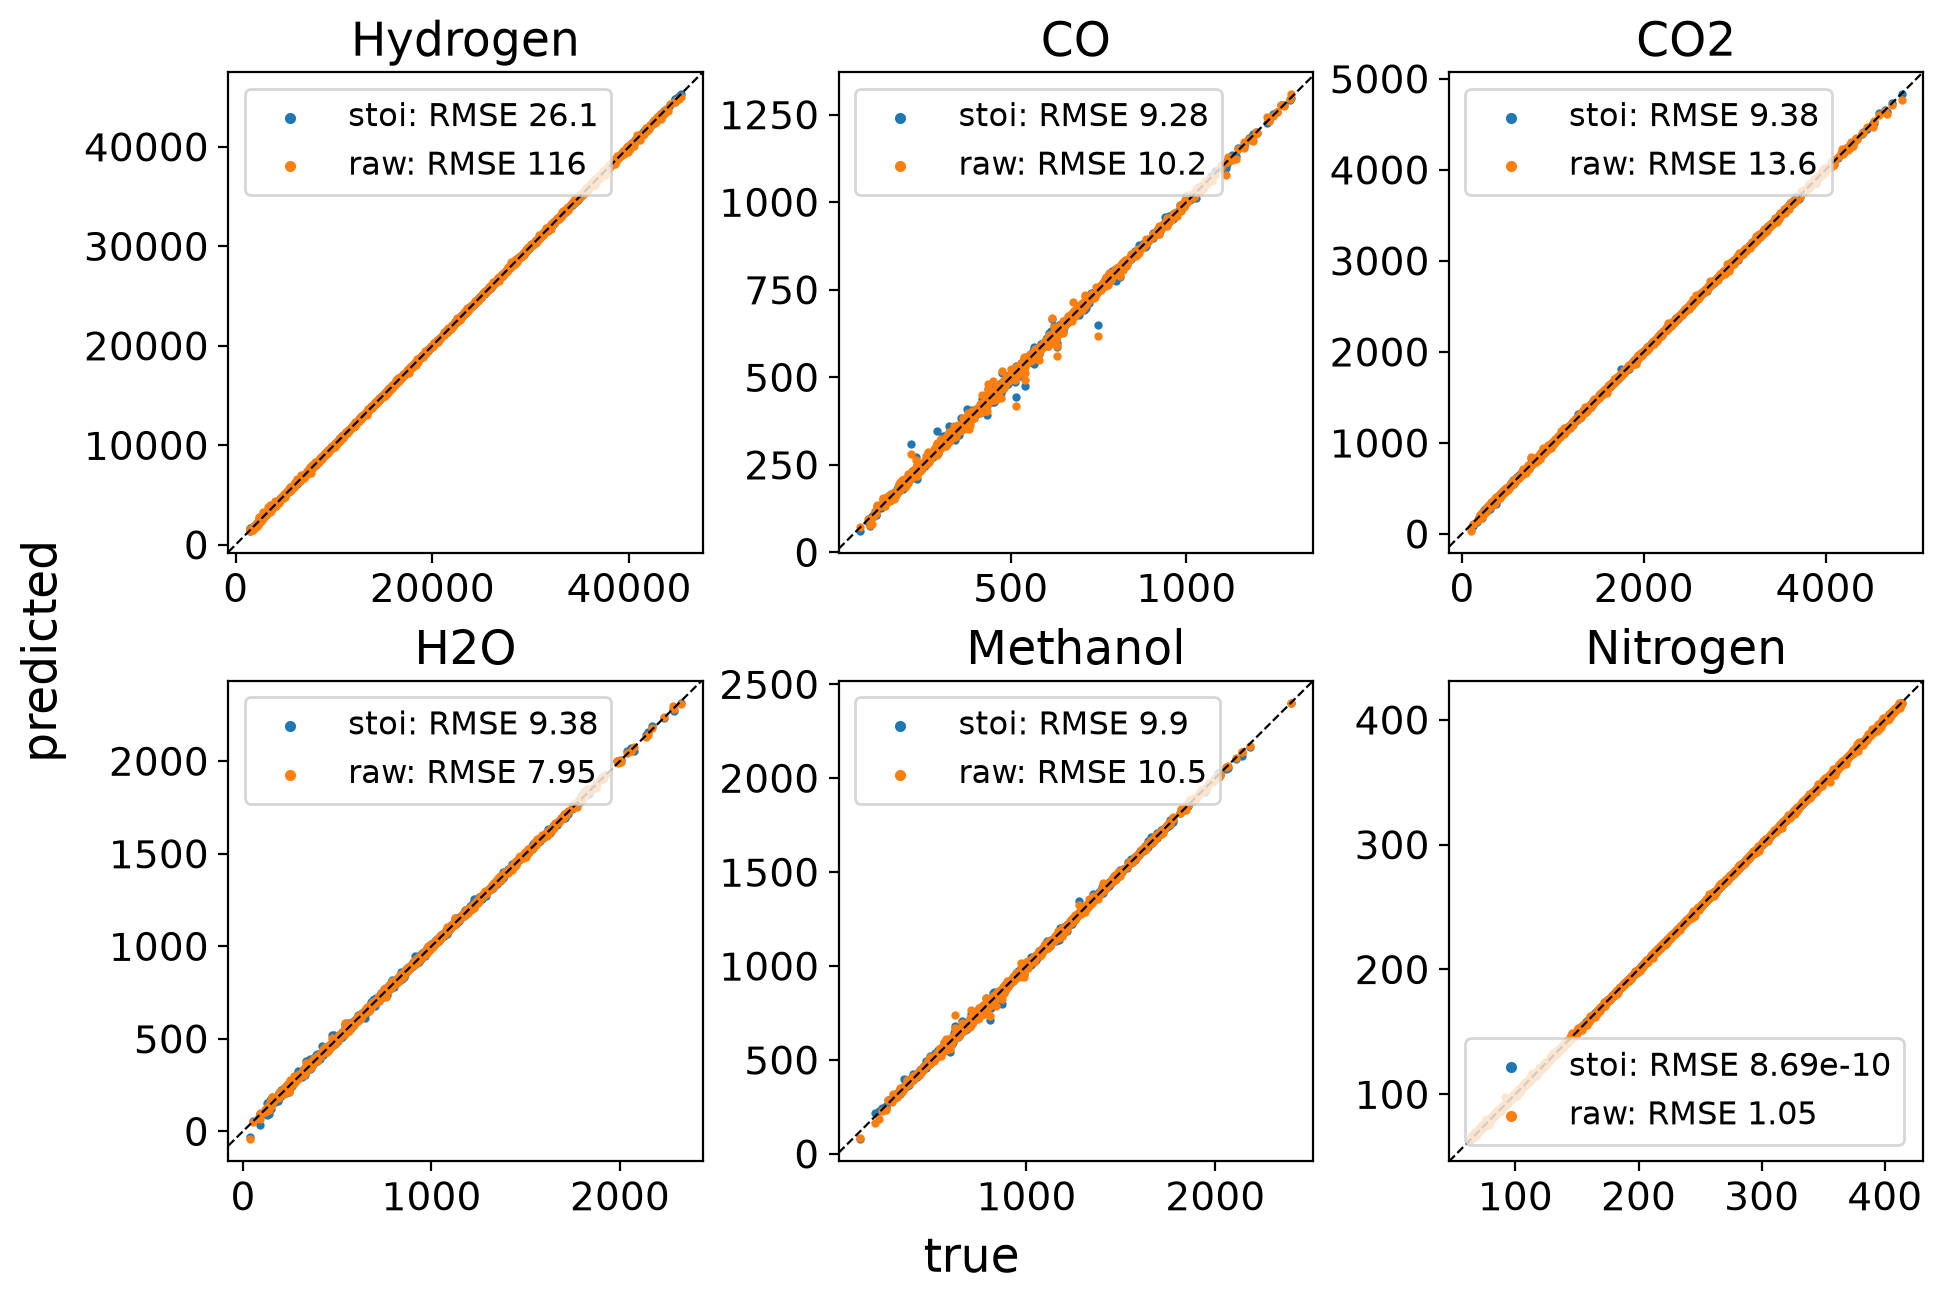

In [14]:
# Side by side on the same footing: outlet flows, with the stoi outlets rebuilt from its
# out-of-fold extents, and the atom balances of the raw net's outlets
inlet = pfr_ok[[f"in_{c}_kgmole_h" for c in sur.COMPONENTS]].to_numpy()
outlet = pfr_ok[[f"out_{c}_kgmole_h" for c in sur.COMPONENTS]].to_numpy()
out_stoi = inlet + oof_stoi[:, :2] @ sur.STOICH.T
comparison = pd.DataFrame({
    "range": outlet.max(0) - outlet.min(0),
    "stoi_rmse": np.sqrt(((out_stoi - outlet) ** 2).mean(0)),
    "raw_rmse": np.sqrt(((oof_raw[:, :6] - outlet) ** 2).mean(0)),
}, index=sur.COMPONENTS).round(2)
print("out-of-fold RMSE of outlet flows [kgmole/h]:")
print(comparison)

ATOMS = {"C": [0, 1, 1, 0, 1, 0], "O": [0, 1, 2, 1, 1, 0], "H": [2, 0, 0, 2, 4, 0]}   # per sur.COMPONENTS
print()
print("raw net atom balance error, out minus in [kgmole/h]  (stoi: zero by construction):")
for atom, v in ATOMS.items():
    err = (oof_raw[:, :6] - inlet) @ np.array(v, float)
    print(f"  {atom}: rms {np.sqrt((err ** 2).mean()):7.2f}   max {np.abs(err).max():7.2f}")
fig, _ = parity_plot(outlet, {"stoi": out_stoi, "raw": oof_raw[:, :6]}, names=sur.COMPONENTS)
save(fig, f"Cases/HYSYS_MeOH_4D/parity_pfr_outlets{TAG}")

In [15]:
# Sanity check on one point: both surrogates against HYSYS
row = pfr_ok.iloc[0]
x = row[list(pfr_box)].to_numpy(dtype=float)
pred = {name: net(x)[:6] for name, net in nets.items()}
for i, c in enumerate(sur.COMPONENTS):
    print(f"  {c:9s} HYSYS {row[f'out_{c}_kgmole_h']:9.2f}   stoi {pred['stoi'][i]:9.2f}   raw {pred['raw'][i]:9.2f} kgmole/h")

  Hydrogen  HYSYS  35698.92   stoi  35706.19   raw  35689.63 kgmole/h
  CO        HYSYS    341.63   stoi    336.88   raw    333.80 kgmole/h
  CO2       HYSYS    867.90   stoi    873.14   raw    881.29 kgmole/h
  H2O       HYSYS   1121.51   stoi   1116.13   raw   1109.59 kgmole/h
  Methanol  HYSYS    890.66   stoi    889.67   raw    890.55 kgmole/h
  Nitrogen  HYSYS    275.15   stoi    275.15   raw    276.29 kgmole/h


## Part D: the loop with the surrogate in place of the PFR

In [16]:
# The cut flowsheet: RoutV is written from the net each tear pass, the rest is solved by HYSYS
objects_sur = sur.cache_objects(case_sur, pfr_box)

def row_surrogate(x, net):
    T, P, ratio, purge = x
    row = sur.run_point(objects_sur, net, pressure=(P, "bar"), temperature=(T, "C"),
                        ratio=ratio, purge_rate=purge, warm=nearest_state(x, WARM["surrogate"]))
    if row["converged"]:
        WARM["surrogate"].append((np.asarray(x, float), row["tear_state"]))
    return row


In [17]:
# Point-wise validation against the HYSYS rows of Part B, both nets
KEYS = ["methanol_kg_h", "compression_kW", "co_formation_kgmole_h", "recycle_ratio"]
for name, net in nets.items():
    t0 = time.time()
    pred = loop_rows(hull_ok[list(design_bounds)].to_numpy(), partial(row_surrogate, net=net))
    conv = pred["converged"].to_numpy()
    print(f"=== {name}: {int(conv.sum())}/{len(pred)} converged, mean {pred.tear_passes.mean():.0f} tear passes, "
          f"{int(pred.outside_box.dropna().map(len).gt(0).sum())} points outside the box, {time.time() - t0:.0f} s")
    for k in KEYS:
        err = (pred[k] - hull_ok[k])[conv]
        rmse = np.sqrt((err ** 2).mean())
        print(f"  {k:22s} rmse {rmse:9.3f}   max |err| {err.abs().max():9.3f}   "
              f"({100 * rmse / hull_ok[k].abs().mean():.2f} % of mean)")

25/256 0.5 min elapsed


50/256 0.9 min elapsed


75/256 1.4 min elapsed


100/256 1.8 min elapsed


125/256 2.3 min elapsed


...

175/256 2.8 min elapsed


200/256 3.2 min elapsed


225/256 3.5 min elapsed


250/256 3.9 min elapsed


256/256 4.0 min elapsed
=== raw: 256/256 converged, mean 18 tear passes, 2 points outside the box, 237 s
  methanol_kg_h          rmse   432.616   max |err|  2060.031   (2.58 % of mean)
  compression_kW         rmse    29.969   max |err|   345.410   (0.76 % of mean)
  co_formation_kgmole_h  rmse     0.844   max |err|     5.523   (6.00 % of mean)
  recycle_ratio          rmse     0.448   max |err|     2.710   (10.12 % of mean)


## Part E: feasibility analysis, surrogate loop against the HYSYS benchmark

In [18]:
def nested_sample_flowsheet(box, model, constraints, *, n_live, n_prop, max_time=0):
    """Nested-sample the region where constraints(model(x)) <= 0 over `box`
    ({name: [lb, ub]}, order defines x).  Returns the sampler Result and a
    DataFrame with one row per evaluation, failed ones included."""
    rows = []

    def g(x):
        row = {**dict(zip(box, x)), **model(x)}
        rows.append(row)                          # kept even if the constraints raise
        residuals = constraints(row)
        row["max_residual"] = max(residuals)      # <= 0 means feasible
        return residuals

    lb, ub = zip(*box.values())
    result = NestedSampler(g, lb, ub, num_live=n_live, num_prop=n_prop, max_time=max_time, display_iter=1).sample()
    return result, pd.DataFrame(rows)

In [19]:
# perform nested sampling on both surrogate and original flowsheets
runs = {}
for name, model in (("surrogate", partial(row_surrogate, net=nets[NET])), ("hysys", row_hysys)):
    t0 = time.time()
    result, df = nested_sample_flowsheet(design_bounds, model, partial(constraints, relax = RELAX if name=="surrogate" else 0),
                                         n_live=N_LIVE_SUR if name == "surrogate" else N_LIVE, n_prop=N_PROP, max_time=MAX_TIME)
    df["feasible"] = df["max_residual"] <= 0
    runs[name] = dict(result=result, df=df, wall_s=time.time() - t0)
    print(f"=== {name}: {len(df)} evaluations, {int(df.feasible.sum())} feasible, "
          f"{result.stats.failures} failed, status {result.status.name}, {runs[name]['wall_s']:.0f} s")


** INITIALIZING LIVE POINTS 

(512)    479.51 SEC


Iterate        Contour #Feas    #Dead         Factor


----------------------------------------------------


      0     7.6351e+03    25        0     3.0000e-01


...

    405     2.5265e-04   511     1824     1.4718e-01


    407    -1.0582e-03   513     1826     1.4707e-01


** EVALUATIONS:       7008 (0 FAILED)


** WALL TIME:     42098.80 SEC


=== hysys: 7008 evaluations, 513 feasible, 0 failed, status NORMAL, 42099 s


In [ ]:
# Verification: surrogate-feasible points re-evaluated on HYSYS, shuffled, until N_LIVE are confirmed
# (live points are sorted by margin: taking them in order would under-sample the boundary; as in the cascades)
sur_df, hys_df = runs["surrogate"]["df"], runs["hysys"]["df"]
cand = sur_df[sur_df.feasible].sample(frac=1, random_state=42)
checks, n_confirmed, t0 = [], 0, time.time()
for x in cand[list(design_bounds)].to_numpy():
    if n_confirmed >= N_LIVE:
        break
    checks.append(row_hysys(x))
    n_confirmed += checks[-1]["converged"] and max(constraints(checks[-1], relax=0)) <= 0
t_ver = time.time() - t0                                   # s, wall time of verification
cand = cand.iloc[:len(checks)].copy()
cand["hysys_max_residual"] = [max(constraints(c, relax=0)) if c["converged"] else np.nan for c in checks]
cand["verified"] = cand.hysys_max_residual <= 0
print(f"{len(cand)} of {int(sur_df.feasible.sum())} surrogate-feasible points re-run on HYSYS in {t_ver:.0f} s: "
      f"{int(cand.verified.sum())} confirmed, {int((~cand.verified).sum())} rejected")


In [ ]:
# Figures: corner and trellis plots, as in the cascades
LABELS = [r"T [$^\circ$C]", "P [bar]", "H$_2$:CO$_2$ [-]", "purge [-]"]
BOX = list(zip(*design_bounds.values()))                    # lower row, upper row
T, P, RATIO, PURGE = range(4)
RATIO_EDGES, PURGE_EDGES = np.linspace(2.5, 4.0, 4), [0.015, 0.02, 0.03, 0.08]   # trellis bins: columns, rows
TRELLIS_KW = dict(xlabel=LABELS[T], ylabel=LABELS[P], col_label=LABELS[RATIO], row_label=LABELS[PURGE],
                  subplot_kw={"xlim": design_bounds["temperature_C"], "ylim": design_bounds["pressure_bar"]})

hys_live, hys_dead = runs["hysys"]["result"].live, runs["hysys"]["result"].dead      # HYSYS benchmark
hys_feasible = hys_df.loc[hys_df.feasible, list(design_bounds)].to_numpy()           # its feasible points
sur_verified = cand.loc[cand.verified, list(design_bounds)].to_numpy()               # verified surrogate candidates
sur_rejected = cand.loc[~cand.verified, list(design_bounds)].to_numpy()              # rejected ones


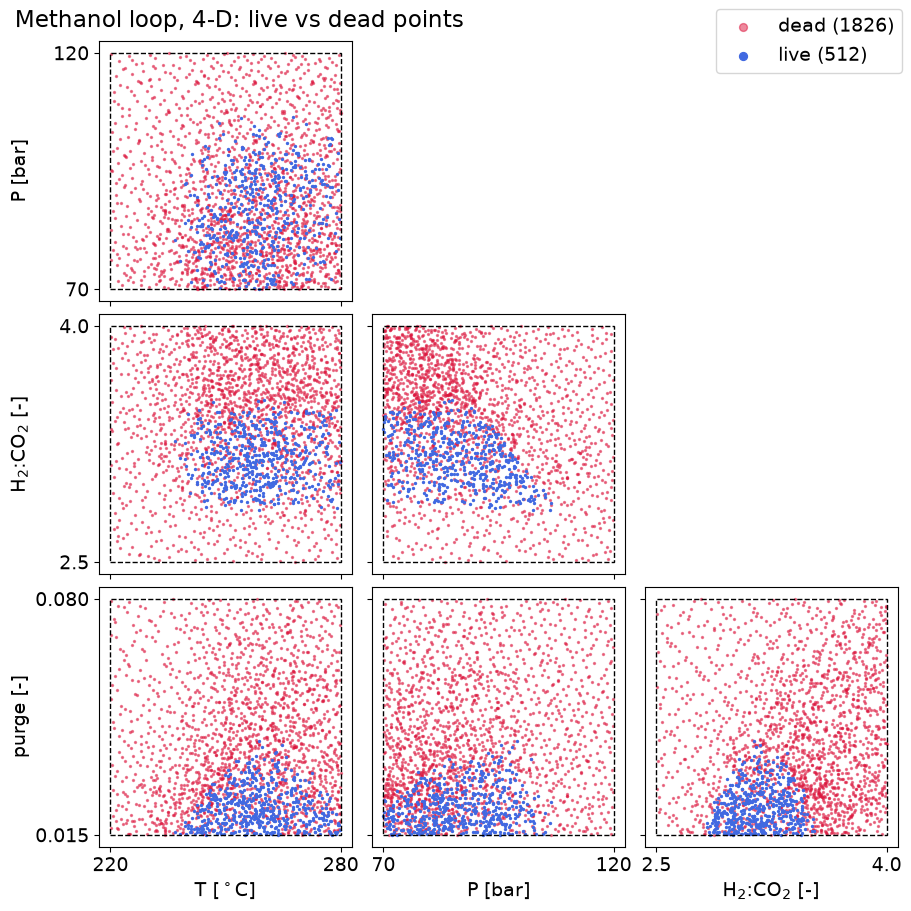

In [ ]:
# Corner: live vs dead points of the HYSYS benchmark
grid = Corner(LABELS, BOX)
grid.scatter(hys_dead.x, s=2, alpha=0.5, color="crimson", label=f"dead ({len(hys_dead.x)})")
grid.scatter(hys_live.x, s=2, color="royalblue", label=f"live ({len(hys_live.x)})")
grid.fig.legend(markerscale=4)
grid.fig.suptitle("Methanol loop, 4-D: live vs dead points", x=0.01, ha="left")
save(grid.fig, f"Cases/HYSYS_MeOH_4D/corner_simultaneous{TAG}")


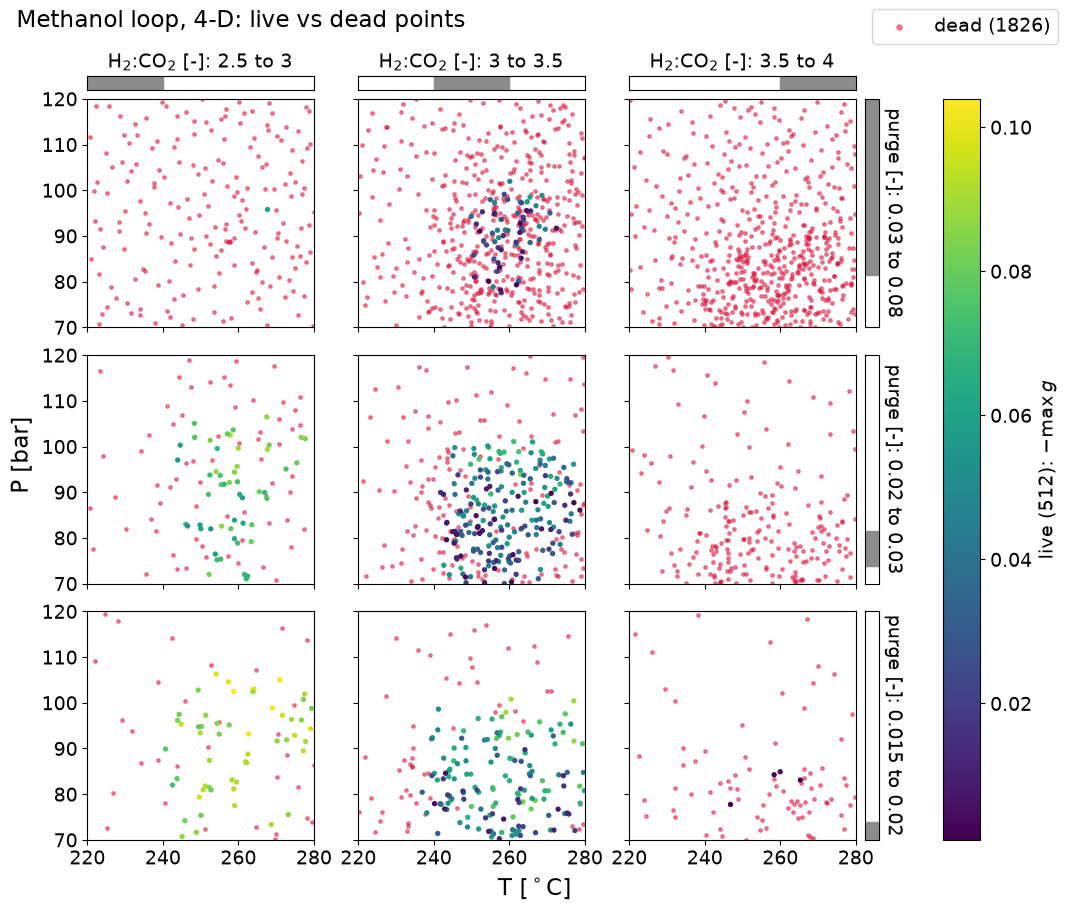

In [ ]:
# Trellis: live vs dead points of the HYSYS benchmark, live coloured by margin
grid = Trellis(RATIO_EDGES, PURGE_EDGES, **TRELLIS_KW)
grid.scatter(hys_dead.x[:, T], hys_dead.x[:, P], hys_dead.x[:, RATIO], hys_dead.x[:, PURGE], s=6, alpha=0.5, color="crimson", label=f"dead ({len(hys_dead.x)})")
pcs = grid.scatter(hys_live.x[:, T], hys_live.x[:, P], hys_live.x[:, RATIO], hys_live.x[:, PURGE], s=8, c=-hys_live.value)
grid.colorbar(pcs[0], label=f"live ({len(hys_live.x)}): $-\\max g$")
grid.fig.legend(loc="outside upper right")
grid.fig.suptitle("Methanol loop, 4-D: live vs dead points", x=0.01, ha="left")
save(grid.fig, f"Cases/HYSYS_MeOH_4D/trellis_simultaneous{TAG}")


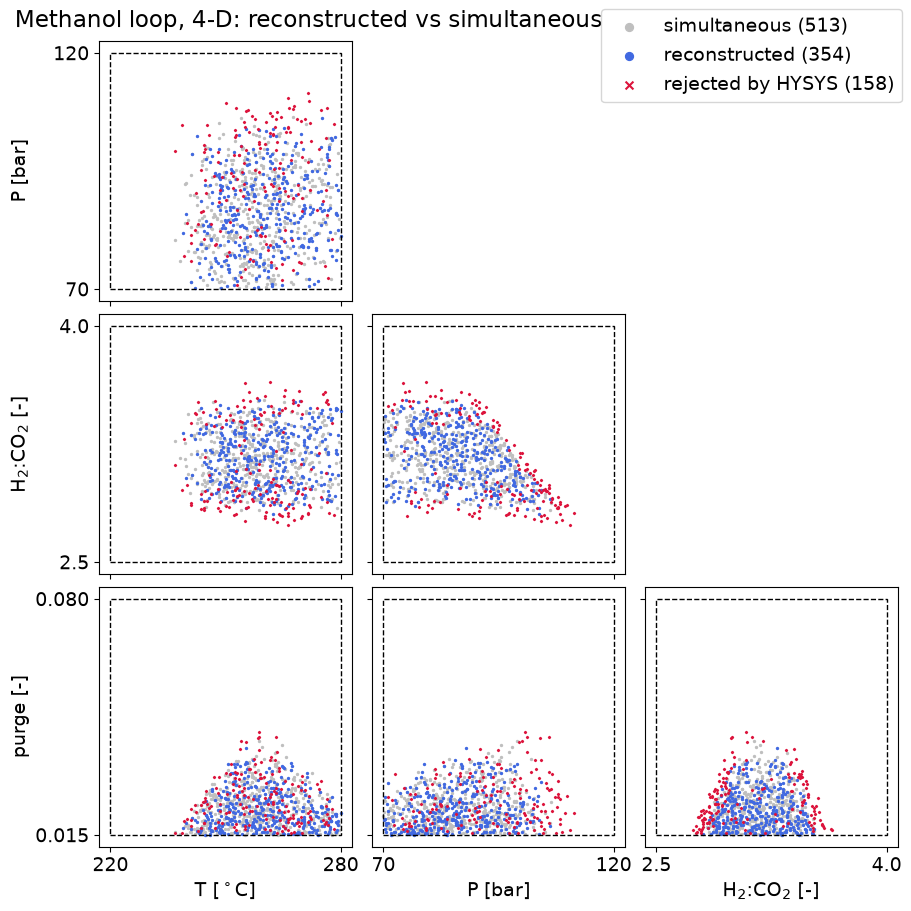

In [ ]:
# Corner: reconstructed (verified surrogate candidates) vs simultaneous
grid = Corner(LABELS, BOX)
grid.scatter(hys_feasible, s=2, color="0.75", label=f"simultaneous ({len(hys_feasible)})")
grid.scatter(sur_verified, s=2, color="royalblue", label=f"reconstructed ({len(sur_verified)})")
grid.scatter(sur_rejected, s=2, marker="x", color="crimson", label=f"rejected by HYSYS ({len(sur_rejected)})")
grid.fig.legend(markerscale=4)
grid.fig.suptitle("Methanol loop, 4-D: reconstructed vs simultaneous", x=0.01, ha="left")
save(grid.fig, f"Cases/HYSYS_MeOH_4D/corner_reconstructed{TAG}")


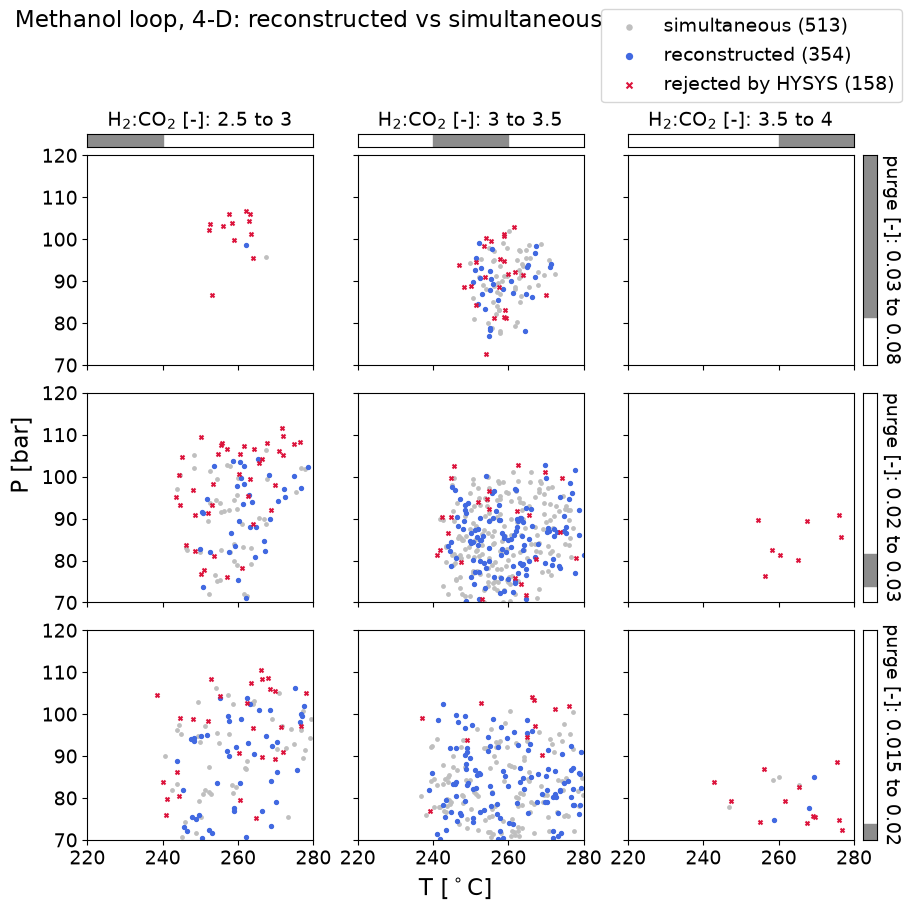

In [ ]:
# Trellis: reconstructed (verified surrogate candidates) vs simultaneous
grid = Trellis(RATIO_EDGES, PURGE_EDGES, **TRELLIS_KW)
grid.scatter(hys_feasible[:, T], hys_feasible[:, P], hys_feasible[:, RATIO], hys_feasible[:, PURGE], s=6, color="0.75", label=f"simultaneous ({len(hys_feasible)})")
grid.scatter(sur_verified[:, T], sur_verified[:, P], sur_verified[:, RATIO], sur_verified[:, PURGE], s=8, color="royalblue", label=f"reconstructed ({len(sur_verified)})")
grid.scatter(sur_rejected[:, T], sur_rejected[:, P], sur_rejected[:, RATIO], sur_rejected[:, PURGE], s=8, marker="x", color="crimson", label=f"rejected by HYSYS ({len(sur_rejected)})")
grid.fig.legend(loc="outside upper right")
grid.fig.suptitle("Methanol loop, 4-D: reconstructed vs simultaneous", x=0.01, ha="left")
save(grid.fig, f"Cases/HYSYS_MeOH_4D/trellis_reconstructed{TAG}")


In [ ]:
KEEP = ["df_sweep", "df_hull", "pfr_box", "df_pfr", "runs", "cand", "t_hull", "t_pfr", "t_train", "t_ver"]
with open(f"backup_4d{TAG}.pkl", "wb") as f:
    pickle.dump({k: globals()[k] for k in KEEP if k in globals()}, f)


In [ ]:
def benchmark():
    """Decomposition (Parts B to E, net NET) against nested sampling of the HYSYS loop, in flowsheet
    equivalents as in the cascades (1 EQ = one solve of the HYSYS loop; PFR solves count by solver time;
    surrogate evaluations at no flowsheet cost by convention) and in wall time, where the surrogate loop
    is not free: HYSYS still solves the separation every tear pass."""
    sur_df, hys_df = runs["surrogate"]["df"], runs["hysys"]["df"]
    s_loop = df_hull.solve_time_s.mean()                                   # s per HYSYS loop solve
    eq_hull, eq_pfr, eq_ver = len(df_hull), df_pfr.solve_time_s.sum() / s_loop, len(cand)
    eq_dec, eq_sim = eq_hull + eq_pfr + eq_ver, len(hys_df)
    print(f"decomposition: {eq_dec:.0f} EQ (inlet domain {eq_hull}, PFR sampling {eq_pfr:.0f}, verification {eq_ver}; "
          f"surrogate sampling {len(sur_df)} evaluations at no flowsheet cost)")
    print(f"true feasible rate {100 * cand.verified.mean():.2f} %")
    print(f"simultaneous {eq_sim} EQ")
    print(f"reduction: {100 * (1 - eq_dec / eq_sim):.1f} %")
    print(f"cost ratio: {eq_sim / eq_dec:.1f} (#simultaneous / #decomposed)")
    t_sur, t_sim = runs["surrogate"]["wall_s"], runs["hysys"]["wall_s"]
    t_dec = t_hull + t_pfr + t_train[NET] + t_sur + t_ver
    print(f"wall time: decomposition {t_dec / 60:.1f} min (inlet domain {t_hull / 60:.1f}, PFR sampling {t_pfr / 60:.1f}, "
          f"training {t_train[NET] / 60:.1f}, surrogate sampling {t_sur / 60:.1f}, verification {t_ver / 60:.1f}) "
          f"vs simultaneous {t_sim / 60:.1f} min, speed-up {t_sim / t_dec:.1f}")

benchmark()


decomposition: 775 EQ (inlet domain 256, PFR sampling 7, verification 512; surrogate sampling 6000 evaluations at no flowsheet cost)
true feasible rate 69.14 %
simultaneous 7008 EQ
reduction: 88.9 %
cost ratio: 9.0 (#simultaneous / #decomposed)
wall time: decomposition 186.3 min (inlet domain 29.3, PFR sampling 0.9, training 0.8, surrogate sampling 90.4, verification 64.9) vs simultaneous 701.6 min, speed-up 3.8
